# GSaS fit of a ticker

Download a ticker's daily prices from Yahoo, fit GSaS to its daily returns with `GSaS_Fit`, and plot the fit. Nothing is written to disk.

**Imports.** `yfinance` downloads the prices, and `GSaS_Fit` (in `gas_impl/gsas_fit.py`) does the fitting. The rest is plotting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import chi2
from matplotlib.patches import Ellipse

from gas_impl.gsas_fit import GSaS_Fit

%config InlineBackend.figure_format = 'retina'

**Parameters.** Choose any Yahoo symbol and the number of years of history to keep.

In [2]:
TICKER = 'QQQ'    # e.g. SPY, QQQ, AAPL, GLD, TLT, BTC-USD, ^GSPC
YEARS = 20         # keep at most this many years of daily returns

**Data.** This downloads the Adjusted Close, drops today's incomplete bar and computes simple daily returns, keeping the last `YEARS` years. Crypto trades every day, so for a `-USD` symbol the returns are taken close-to-close on weekdays only.

In [3]:
px = yf.download(TICKER, period='max', auto_adjust=False, progress=False)['Adj Close']
if isinstance(px, pd.DataFrame):                  # yfinance returns one column per ticker
    px = px.iloc[:, 0]
px = px.dropna()
px = px[px.index.normalize() < pd.Timestamp.today().normalize()]
if TICKER.endswith('-USD'):
    px = px[px.index.dayofweek < 5]
xs = px.pct_change().dropna()
xs = xs.loc[xs.index[-1] - pd.DateOffset(years=YEARS):]
x = xs.values
print(f"{TICKER}: {len(x)} daily returns, {xs.index[0].date()} .. {xs.index[-1].date()}")

QQQ: 5032 daily returns, 2006-11-20 .. 2026-11-20


**Fit.** `GSaS_Fit(x)` measures the excess kurtosis and the standardized peak density (SPD), maps them to the plane coordinates $(v_1, v_2)$, and solves for $(\alpha, k)$. `bootstrap_shape()` resamples 20-day blocks to give the sampling uncertainty of $(v_1, v_2)$ and of the skew.

In [4]:
FIT = GSaS_Fit(x)
SHAPE = FIT.shape
assert FIT.status == 'ok', f"{TICKER}: {FIT.status}"
ALPHA, K, XI = FIT.alpha, FIT.k, FIT.xi

BOOT = FIT.bootstrap_shape()                      # DataFrame with columns v1, v2, skew
BOOT_COV = np.cov(BOOT[['v1', 'v2']].values.T)
lo95, hi95 = np.percentile(BOOT['v2'] - BOOT['v1'], [2.5, 97.5])
sk_lo, sk_hi = np.percentile(BOOT['skew'], [2.5, 97.5])
print(pd.Series({
    'n': SHAPE['n'],
    'excess kurtosis': round(SHAPE['exkurt'], 4),
    'SPD': round(SHAPE['SPD'], 4),
    'v1': round(SHAPE['v1'], 4),
    'v2': round(SHAPE['v2'], 4),
    'v2 - v1 [95%]': f"{SHAPE['v2'] - SHAPE['v1']:+.4f} [{lo95:+.4f}, {hi95:+.4f}]",
    'skew [95%]': f"{FIT.skew:+.3f} [{sk_lo:+.3f}, {sk_hi:+.3f}]",
    'alpha': round(ALPHA, 4),
    'k': round(K, 3),
    'xi': round(XI, 4),
}).to_string())

n                                        5032
excess kurtosis                        7.3807
SPD                                      0.67
v1                                     0.3103
v2                                     0.3456
v2 - v1 [95%]      +0.0353 [-0.0259, +0.1300]
skew [95%]            -0.089 [-0.440, +0.274]
alpha                                  0.1811
k                                      -14.22
xi                                    -0.0703


**Plane.** This plots the ticker at $(v_1, v_2)$ with its bootstrap region (a 50% ellipse). For reference it draws the LNN diagonal, curves of fixed $k$ (solid for $k>0$, dashed for $k<0$) and Student's t. `label_along` writes each curve's label along the curve after the axes are laid out.

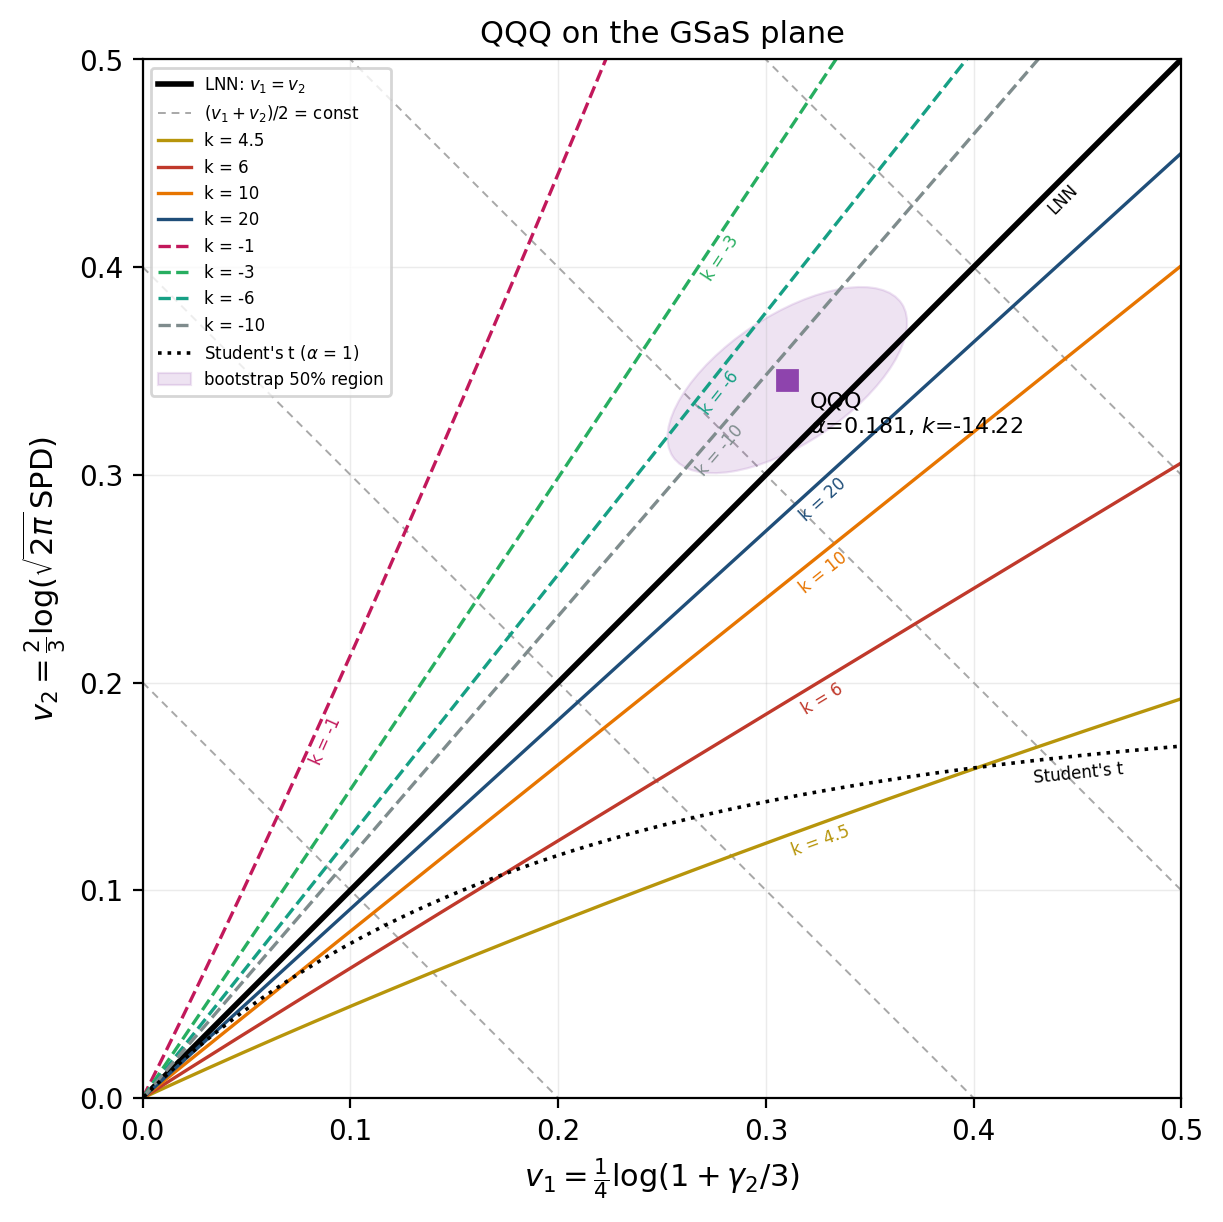

In [5]:
ELLIPSE_LEVEL = 0.50
V_MAX = max(0.5, np.ceil(1.15*max(SHAPE['v1'], SHAPE['v2'])*10)/10)
K_POS = [(4.5, '#b7950b', 8.0), (6, '#c0392b', 8.0), (10, '#E77500', 8.0), (20, '#1f4e79', 8.0)]   # (k, colour, gamma2 to label at)
K_NEG = [(-1.0, '#c2185b', 1.2), (-3.0, '#27ae60', 6.0), (-6.0, '#16a085', 6.0), (-10.0, '#7f8c8d', 6.0)]

def label_along(ax, xs_, ys_, x0, text, c):
    ok = np.isfinite(ys_)
    dx = 0.02*(ax.get_xlim()[1] - ax.get_xlim()[0])
    y0, y1_ = np.interp([x0, x0 + dx], xs_[ok], ys_[ok])
    (px0, py0), (px1, py1) = ax.transData.transform([(x0, y0), (x0 + dx, y1_)])
    ax.annotate(text, (x0, y0), xytext=(0, -3), textcoords='offset points', ha='center', va='top',
                rotation=np.degrees(np.arctan2(py1 - py0, px1 - px0)), rotation_mode='anchor', color=c, fontsize=6)

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
vg = np.linspace(0, V_MAX, 201)
ax.plot(vg, vg, color='black', lw=2.0, label=r'LNN: $v_1=v_2$')
for i, r0 in enumerate(np.arange(0.1, 2*V_MAX, 0.1)):          # level lines of (v1 + v2)/2
    ax.plot([0, 2*r0], [2*r0, 0], color='#a8a8a8', lw=0.7, ls=(0, (4, 3)), zorder=0,
            label=r'$(v_1 + v_2)/2$ = const' if i == 0 else None)
curves = []
for k, c, g0 in K_POS + K_NEG:
    v1c, v2c = GSaS_Fit.plane_k_curve(k, V_MAX)
    ax.plot(v1c, v2c, color=c, lw=1.2, ls='-' if k > 0 else '--', label=f'k = {k:g}')
    curves.append((v1c, v2c, f'k = {k:g}', c, g0))
t_v1, t_v2 = GSaS_Fit.plane_student_t(V_MAX)
ax.plot(t_v1, t_v2, color='black', lw=1.3, ls=':', label=r"Student's t ($\alpha$ = 1)")

v1d, v2d = SHAPE['v1'], SHAPE['v2']
w, U = np.linalg.eigh(BOOT_COV)
q = chi2.ppf(ELLIPSE_LEVEL, 2)
ax.add_patch(Ellipse((v1d, v2d), 2*np.sqrt(q*w[1]), 2*np.sqrt(q*w[0]), angle=np.degrees(np.arctan2(U[1, 1], U[0, 1])),
                     fc='#8e44ad', ec='#8e44ad', alpha=0.15, lw=0.8, zorder=1, label=f'bootstrap {ELLIPSE_LEVEL:.0%} region'))
ax.plot(v1d, v2d, 's', color='#8e44ad', ms=7, zorder=3)
ax.annotate(f'{TICKER}\n' + rf'$\alpha$={ALPHA:.3f}, $k$={K:.2f}', (v1d, v2d), textcoords='offset points', xytext=(8, -4),
            ha='left', va='top', fontsize=8)
ax.set_xlabel(r'$v_1 = \frac{1}{4}\log(1 + \gamma_2/3)$', fontsize=11)
ax.set_ylabel(r'$v_2 = \frac{2}{3}\log(\sqrt{2\pi}\,\mathrm{SPD})$', fontsize=11)
ax.set_title(f'{TICKER} on the GSaS plane', fontsize=11)
ax.set_xlim(0, V_MAX); ax.set_ylim(0, V_MAX); ax.set_aspect('equal'); ax.grid(alpha=0.25, lw=0.5)
ax.legend(fontsize=6, loc='upper left')
fig.canvas.draw()                                               # labels are angled on screen, so lay out first
for v1c, v2c, text, c, g0 in curves:
    label_along(ax, v1c, v2c, np.log1p(g0/3)/4, text, c)
label_along(ax, vg, vg, 0.88*V_MAX, 'LNN', 'black')
label_along(ax, t_v1, t_v2, 0.9*V_MAX, "Student's t", 'black')
plt.show()

**Density and Q-Q.** This compares the fitted GSaS with the data: a histogram with the fitted pdf on linear and log scales, and a Q-Q plot whose points fall on the diagonal when the fit is good. The fit uses the sample mean as its location and matches the sample sd.

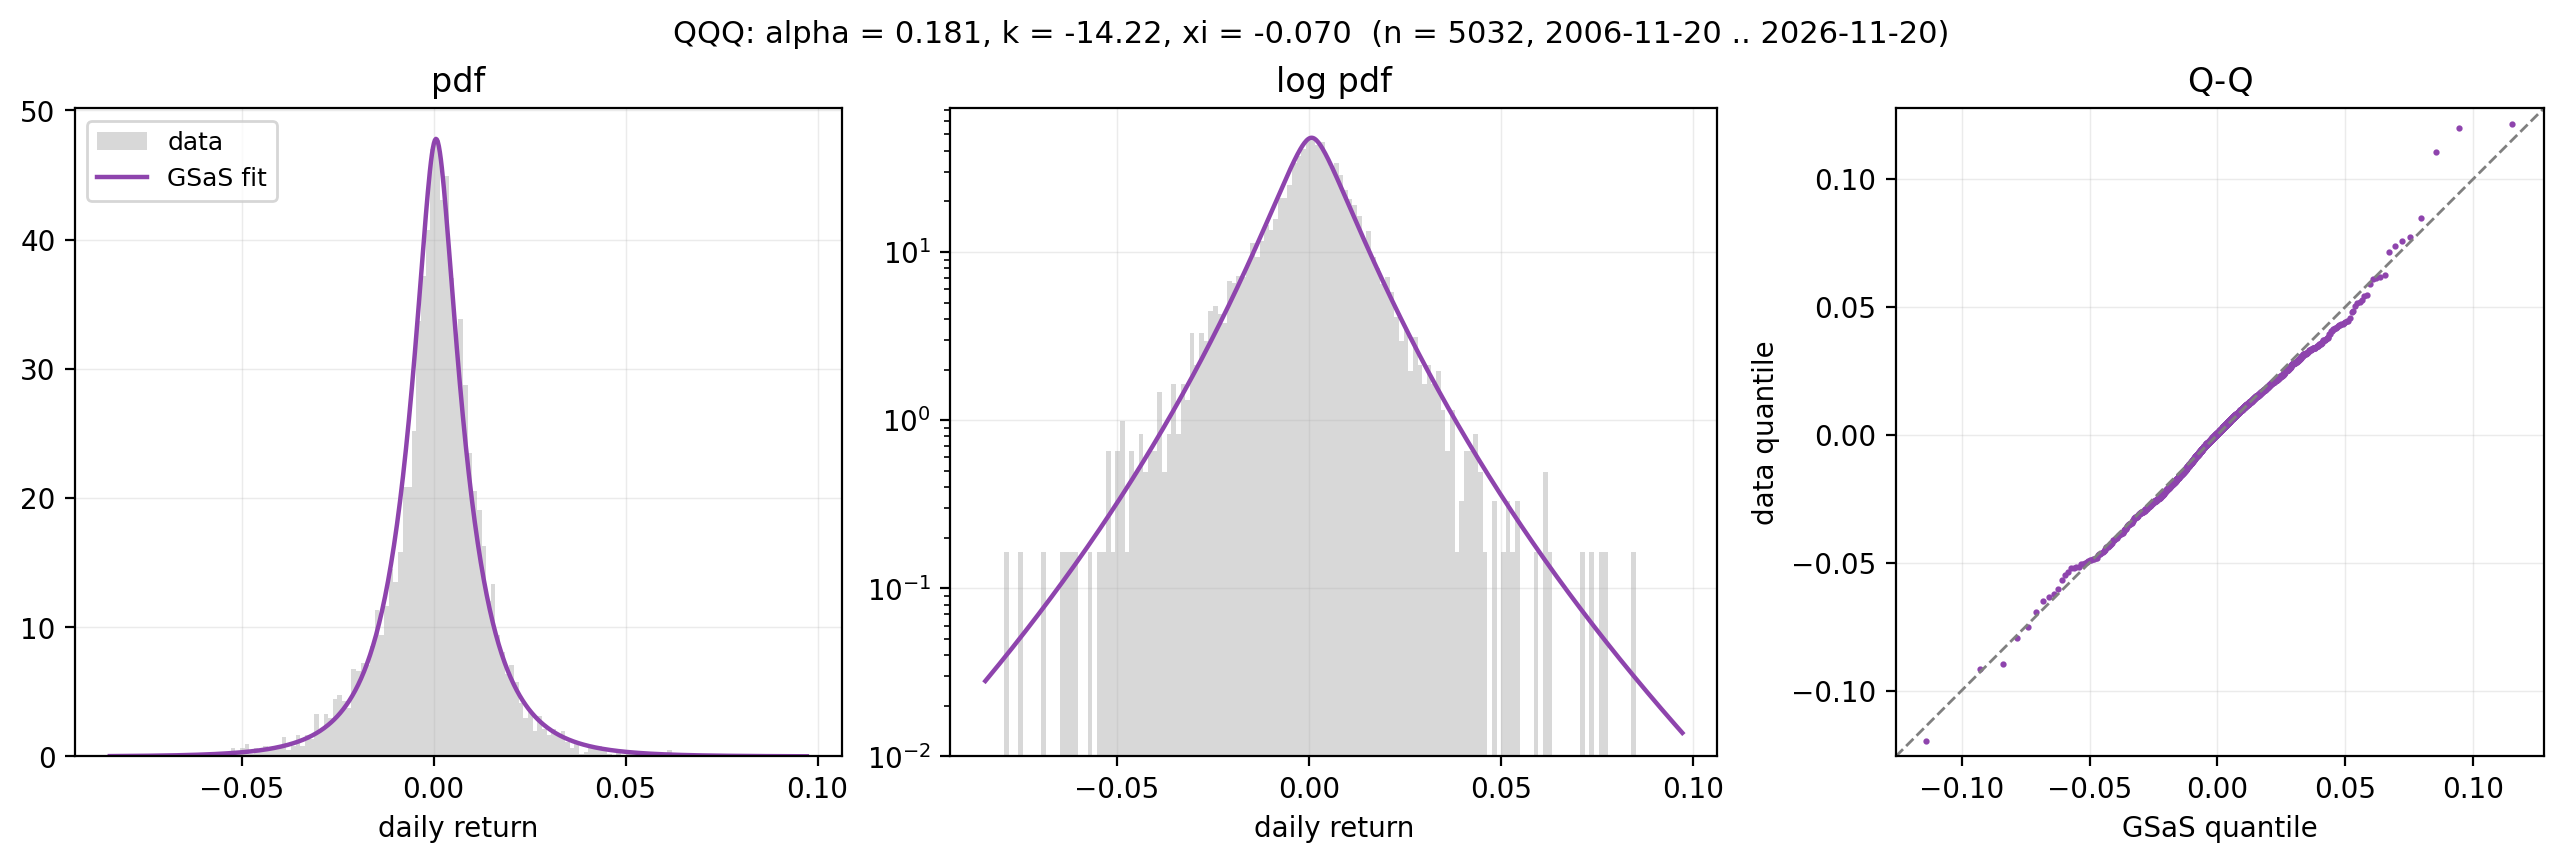

In [6]:
lo, hi = np.percentile(x, [0.05, 99.95])
grid = np.linspace(lo, hi, 700)
pdf_fit = FIT.pdf(grid)
q_fit, x_sorted = FIT.qq()
lim = [x_sorted[0]*1.05, x_sorted[-1]*1.05]
col = '#8e44ad'

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
for a in axes[:2]:
    a.hist(x, bins=150, range=(lo, hi), density=True, color='grey', alpha=0.30, label='data')
    a.plot(grid, pdf_fit, color=col, lw=1.6, label='GSaS fit')
    a.set_xlabel('daily return'); a.grid(alpha=0.25, lw=0.5); a.locator_params(axis='x', nbins=5)
axes[0].set_title('pdf'); axes[0].legend(fontsize=9, loc='upper left')
axes[1].set_title('log pdf'); axes[1].set_yscale('log'); axes[1].set_ylim(max(1e-2, 0.5*pdf_fit.min()), None)
a = axes[2]
a.plot(q_fit, x_sorted, '.', ms=2.5, color=col)
a.plot(lim, lim, color='grey', lw=1, ls='--')
a.set_xlim(lim); a.set_ylim(lim); a.set_aspect('equal'); a.grid(alpha=0.25, lw=0.5)
a.set_xlabel('GSaS quantile'); a.set_ylabel('data quantile'); a.set_title('Q-Q')
fig.suptitle(f'{TICKER}: alpha = {ALPHA:.3f}, k = {K:.2f}, xi = {XI:+.3f}  '
             f'(n = {len(x)}, {xs.index[0].date()} .. {xs.index[-1].date()})', fontsize=11)
plt.show()